# Strategy backtest

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

pd.set_option("display.max_columns", None)

## Load the files

In [2]:
train_df = pd.read_csv("train_df.csv", index_col=0)
test_df = pd.read_csv("test_df.csv", index_col=0)
market = pd.read_csv("nifty_index.csv")
regimes = pd.read_csv("causal_test_regimes.csv")
model = joblib.load("hmm_model.joblib")

features = [
    "daily_returns",
    "sign_persistence",
    "rolling_volatility",
    "trend",
]

train_df.index = train_df.index.astype(int)
test_df.index = test_df.index.astype(int)
train_df = train_df[features].astype(float)
test_df = test_df[features].astype(float)

market["Date"] = pd.to_datetime(market["Date"])
market["Close"] = pd.to_numeric(market["Close"], errors="coerce")
market["daily_returns"] = market["Close"].pct_change()

regimes["market_row"] = regimes["market_row"].astype(int)
regimes = regimes.set_index("market_row").sort_index()
regimes["date"] = pd.to_datetime(regimes["date"])
regimes["next_day_return"] = pd.to_numeric(
    regimes["next_day_return"], errors="coerce"
)

if train_df.empty or test_df.empty or regimes.empty:
    raise ValueError("One of the input datasets is empty.")

if train_df.isna().any().any() or test_df.isna().any().any():
    raise ValueError("Train/test features contain missing values.")

if train_df.index.max() >= test_df.index.min():
    raise ValueError("Train and test feature rows overlap.")

if not np.array_equal(regimes.index.to_numpy(), test_df.index[:-1].to_numpy()):
    raise ValueError("Regime rows do not match test rows with a next-day return.")

if regimes["next_day_return"].isna().any():
    raise ValueError("The regime file contains missing next-day returns.")

print("Training rows:", len(train_df))
print("Test feature rows:", len(test_df))
print("Test rows with next-day returns:", len(regimes))
print("Test dates:", regimes["date"].min().date(), "to", regimes["date"].max().date())

Training rows: 3708
Test feature rows: 927
Test rows with next-day returns: 926
Test dates: 2023-01-16 to 2026-10-19


## Get the training regimes

In [3]:
def filter_states(hmm_model, X, previous_probs=None):
    X = np.asarray(X, dtype=float)
    log_emissions = hmm_model._compute_log_likelihood(X)
    log_transition = np.log(np.clip(hmm_model.transmat_, 1e-300, 1.0))
    probabilities = np.zeros((len(X), hmm_model.n_components))

    if previous_probs is None:
        previous = hmm_model.startprob_.copy()
        first_row = True
    else:
        previous = np.asarray(previous_probs, dtype=float)
        previous = previous / previous.sum()
        first_row = False

    for i, emission in enumerate(log_emissions):
        if i == 0 and first_row:
            log_prior = np.log(np.clip(previous, 1e-300, 1.0))
        else:
            log_prior = logsumexp(
                np.log(np.clip(previous, 1e-300, 1.0))[:, None]
                + log_transition,
                axis=0,
            )

        log_posterior = log_prior + emission
        log_posterior -= logsumexp(log_posterior)
        previous = np.exp(log_posterior)
        probabilities[i] = previous

    return probabilities


train_probabilities = filter_states(model, train_df.to_numpy())
train_states = train_probabilities.argmax(axis=1)

market["next_day_return"] = market["daily_returns"].shift(-1)
market["market_row"] = np.arange(len(market))
train_start = int(train_df.index.min())
test_start = int(test_df.index.min())

# The last training feature row predicts a return inside the test period.
# Leave it out when learning the strategy rule.
train_rows = train_df.index.to_numpy()
keep = train_rows < test_start - 1
train_rows = train_rows[keep]
train_states = train_states[keep]

training_results = pd.DataFrame({
    "market_row": train_rows,
    "state": train_states,
    "next_day_return": market.loc[train_rows, "next_day_return"].to_numpy(),
})
training_results = training_results.dropna(subset=["next_day_return"])

state_stats = training_results.groupby("state")["next_day_return"].agg(
    observations="count",
    mean_return="mean",
    volatility="std",
)
state_stats["volatility"] = state_stats["volatility"].fillna(0)

print("Training results by state:")
display(state_stats.round(5))

Training results by state:


,observations,mean_return,volatility
state,,,
0,1003,0.00015,0.01115
1,1004,0.00056,0.00696
2,568,0.00080,0.01910
3,878,0.00020,0.00996
4,254,0.00060,0.03030


## Choose exposure using training data

In [4]:
# Simple risk rule: use less exposure in states with higher return volatility.
# The cutoff is calculated from training states only.
volatility_cutoff = state_stats["volatility"].median()

state_stats["exposure"] = np.where(
    state_stats["volatility"] > volatility_cutoff,
    0.5,
    1.0,
)

print("Training volatility cutoff:", round(float(volatility_cutoff), 6))
display(state_stats.round(5))

test = regimes.copy()
test["hmm_exposure"] = test["state"].map(state_stats["exposure"])

if test["hmm_exposure"].isna().any():
    missing_states = test.loc[test["hmm_exposure"].isna(), "state"].unique()
    raise ValueError(f"No training exposure rule for test states: {missing_states}")

# Baselines use information available at the close of the signal day.
market["momentum_20"] = market["Close"].pct_change(20)
market["momentum_5"] = market["Close"].pct_change(5)

rows = test.index.to_numpy()
test["buy_hold_exposure"] = 1.0
test["momentum_exposure"] = (
    market.loc[rows, "momentum_20"].to_numpy() > 0
).astype(float)
test["mean_reversion_exposure"] = (
    market.loc[rows, "momentum_5"].to_numpy() < 0
).astype(float)

print("Test exposure by state:")
display(test.groupby("state")["hmm_exposure"].agg(["count", "mean"]).round(4))

Training volatility cutoff: 0.011149


,observations,mean_return,volatility,exposure
state,,,,
0,1003,0.00015,0.01115,1.0
1,1004,0.00056,0.00696,1.0
2,568,0.00080,0.01910,0.5
3,878,0.00020,0.00996,1.0
4,254,0.00060,0.03030,0.5


Test exposure by state:


,count,mean
state,,
0,59,1.0
1,535,1.0
2,50,0.5
3,282,1.0


## Run the backtest

In [5]:
cost_per_turnover = 0.001
trading_days = 252

def run_strategy(data, exposure_column):
    result = data[["date", "next_day_return", exposure_column]].copy()
    result = result.rename(columns={exposure_column: "exposure"})
    result = result.sort_values("date").reset_index(drop=True)

    result["turnover"] = result["exposure"].diff().abs()
    if len(result):
        result.loc[0, "turnover"] = abs(result.loc[0, "exposure"])

    result["gross_return"] = result["exposure"] * result["next_day_return"]
    result["cost"] = result["turnover"] * cost_per_turnover
    result["net_return"] = result["gross_return"] - result["cost"]
    result["equity"] = (1 + result["net_return"]).cumprod()
    result["peak"] = result["equity"].cummax()
    result["drawdown"] = result["equity"] / result["peak"] - 1

    years = len(result) / trading_days
    final_value = result["equity"].iloc[-1]
    cagr = final_value ** (1 / years) - 1 if years > 0 and final_value > 0 else np.nan

    daily_volatility = result["net_return"].std(ddof=1)
    sharpe = (
        result["net_return"].mean() / daily_volatility * np.sqrt(trading_days)
        if pd.notna(daily_volatility) and daily_volatility > 0
        else np.nan
    )

    stats = {
        "CAGR": cagr,
        "Sharpe": sharpe,
        "Max drawdown": result["drawdown"].min(),
        "Final value": final_value,
        "Turnover": result["turnover"].sum(),
        "Days invested": int((result["exposure"] > 0).sum()),
    }
    return result, stats


strategies = {
    "HMM risk rule": "hmm_exposure",
    "Buy and hold": "buy_hold_exposure",
    "20-day momentum": "momentum_exposure",
    "5-day mean reversion": "mean_reversion_exposure",
}

backtests = {}
summary = {}

for name, column in strategies.items():
    curve, stats = run_strategy(test, column)
    backtests[name] = curve
    summary[name] = stats

summary_df = pd.DataFrame(summary).T
display(summary_df.sort_values("CAGR", ascending=False).round(4))

,CAGR,Sharpe,Max drawdown,Final value,Turnover,Days invested
Buy and hold,0.0664,0.5697,-0.1577,1.2666,1.0,926.0
HMM risk rule,0.0409,0.3874,-0.1827,1.1588,4.0,926.0
20-day momentum,-0.0094,-0.0596,-0.2005,0.9660,94.0,546.0
5-day mean reversion,-0.0120,-0.0815,-0.1906,0.9564,172.0,425.0


## Plot the results

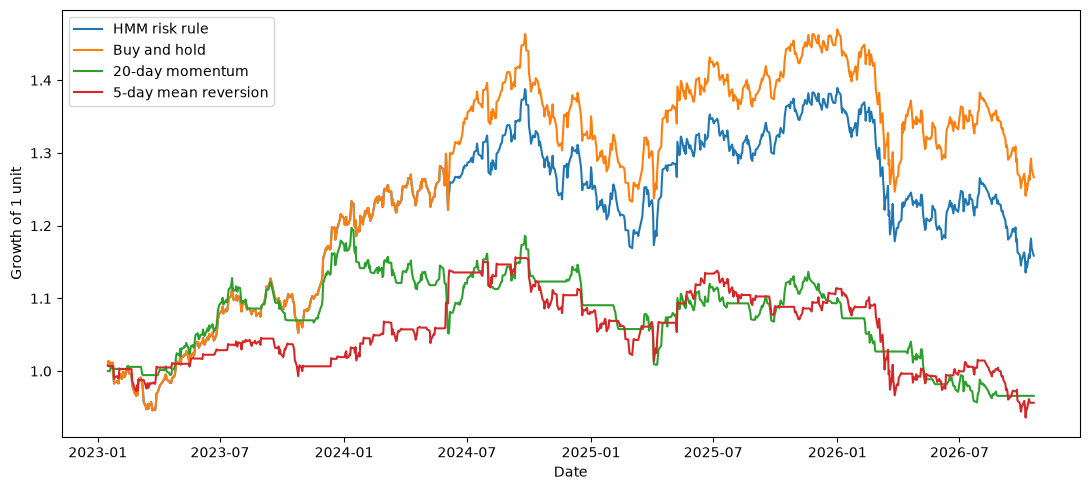

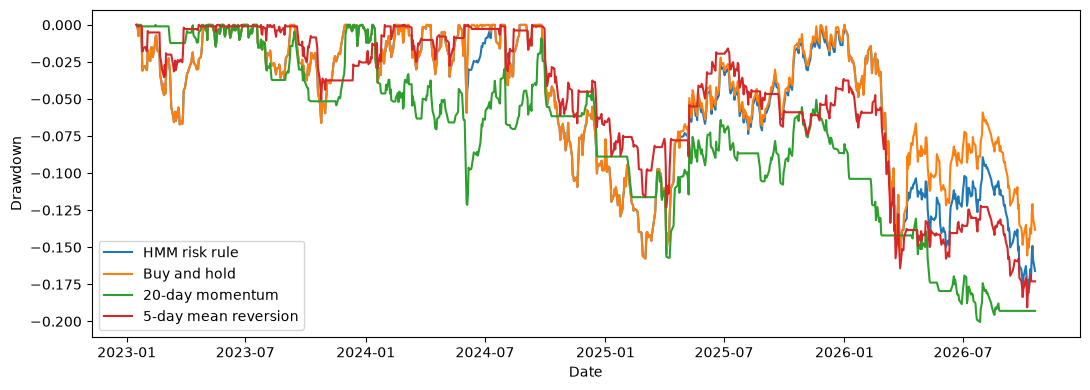

In [6]:
plt.figure(figsize=(11, 5))
for name, curve in backtests.items():
    plt.plot(curve["date"], curve["equity"], label=name)
plt.xlabel("Date")
plt.ylabel("Growth of 1 unit")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4))
for name, curve in backtests.items():
    plt.plot(curve["date"], curve["drawdown"], label=name)
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.legend()
plt.tight_layout()
plt.show()

## Save the results

In [7]:
summary_df.to_csv("strategy_backtest_summary.csv", index_label="strategy")
test.to_csv("test_strategy_signals.csv", index_label="market_row")

for name, curve in backtests.items():
    filename = name.lower().replace(" ", "_").replace("-", "")
    curve.to_csv(f"backtest_{filename}.csv", index=False)

print("Saved the summary, signals and equity curves.")

Saved the summary, signals and equity curves.
